In [1]:
# In thông tin sinh viên theo yêu cầu
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

import pandas as pd

# Đọc file dữ liệu
file_name = 'tb_tracking.xlsx'
df = pd.read_excel(file_name)

# Gán tiêu đề cột theo đúng thứ tự yêu cầu
column_names = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
if len(df.columns) == 6:
    df.columns = column_names
else:
    df = pd.read_excel(file_name, names=column_names)

print("Dữ liệu sau khi thêm tiêu đề các cột:")
display(df.head())

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------
Dữ liệu sau khi thêm tiêu đề các cột:


,id,device_id,co_level,humidity,temperature,time
0,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
1,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
2,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
3,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01
4,6.0,100.0,2.0,3.0,400.0,2016-12-20 13:02:24


In [2]:
# In thông tin sinh viên theo yêu cầu
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# Chuyển đổi cột time về dạng datetime
df['time'] = pd.to_datetime(df['time'])

# Lọc bỏ các dữ liệu trước ngày 03/01/2018
df = df[df['time'] >= '2018-01-03']

print(f"Số lượng dòng dữ liệu sau khi lọc: {len(df)}")
display(df.head())


Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------
Số lượng dòng dữ liệu sau khi lọc: 1918


,id,device_id,co_level,humidity,temperature,time
31418,31420.0,1.0,2.0,3.0,4.0,2018-01-03 13:11:07
31419,31421.0,1.0,2.0,3.0,4.0,2018-01-03 13:15:10
31420,31422.0,99005.0,58.0,26.0,0.0,2018-01-03 13:17:30
31421,31423.0,99005.0,58.0,26.0,0.0,2018-01-03 13:19:21
31422,31424.0,99005.0,58.0,26.0,0.0,2018-01-03 13:24:17


In [3]:
# In thông tin sinh viên theo yêu cầu
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

# Bóc tách thời điểm trong ngày tính theo phút (giờ * 60 + phút + giây / 60)
df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute + df['time'].dt.second / 60

print("Dữ liệu sau khi tạo thêm thuộc tính minutes:")
display(df[['time', 'minutes', 'co_level', 'humidity', 'temperature']].head())

Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------
Dữ liệu sau khi tạo thêm thuộc tính minutes:


,time,minutes,co_level,humidity,temperature
31418,2018-01-03 13:11:07,791.116667,2.0,3.0,4.0
31419,2018-01-03 13:15:10,795.166667,2.0,3.0,4.0
31420,2018-01-03 13:17:30,797.500000,58.0,26.0,0.0
31421,2018-01-03 13:19:21,799.350000,58.0,26.0,0.0
31422,2018-01-03 13:24:17,804.283333,58.0,26.0,0.0


Họ và tên: Vũ Trương Phi
MSSV: 6451071059
----------------------------------------


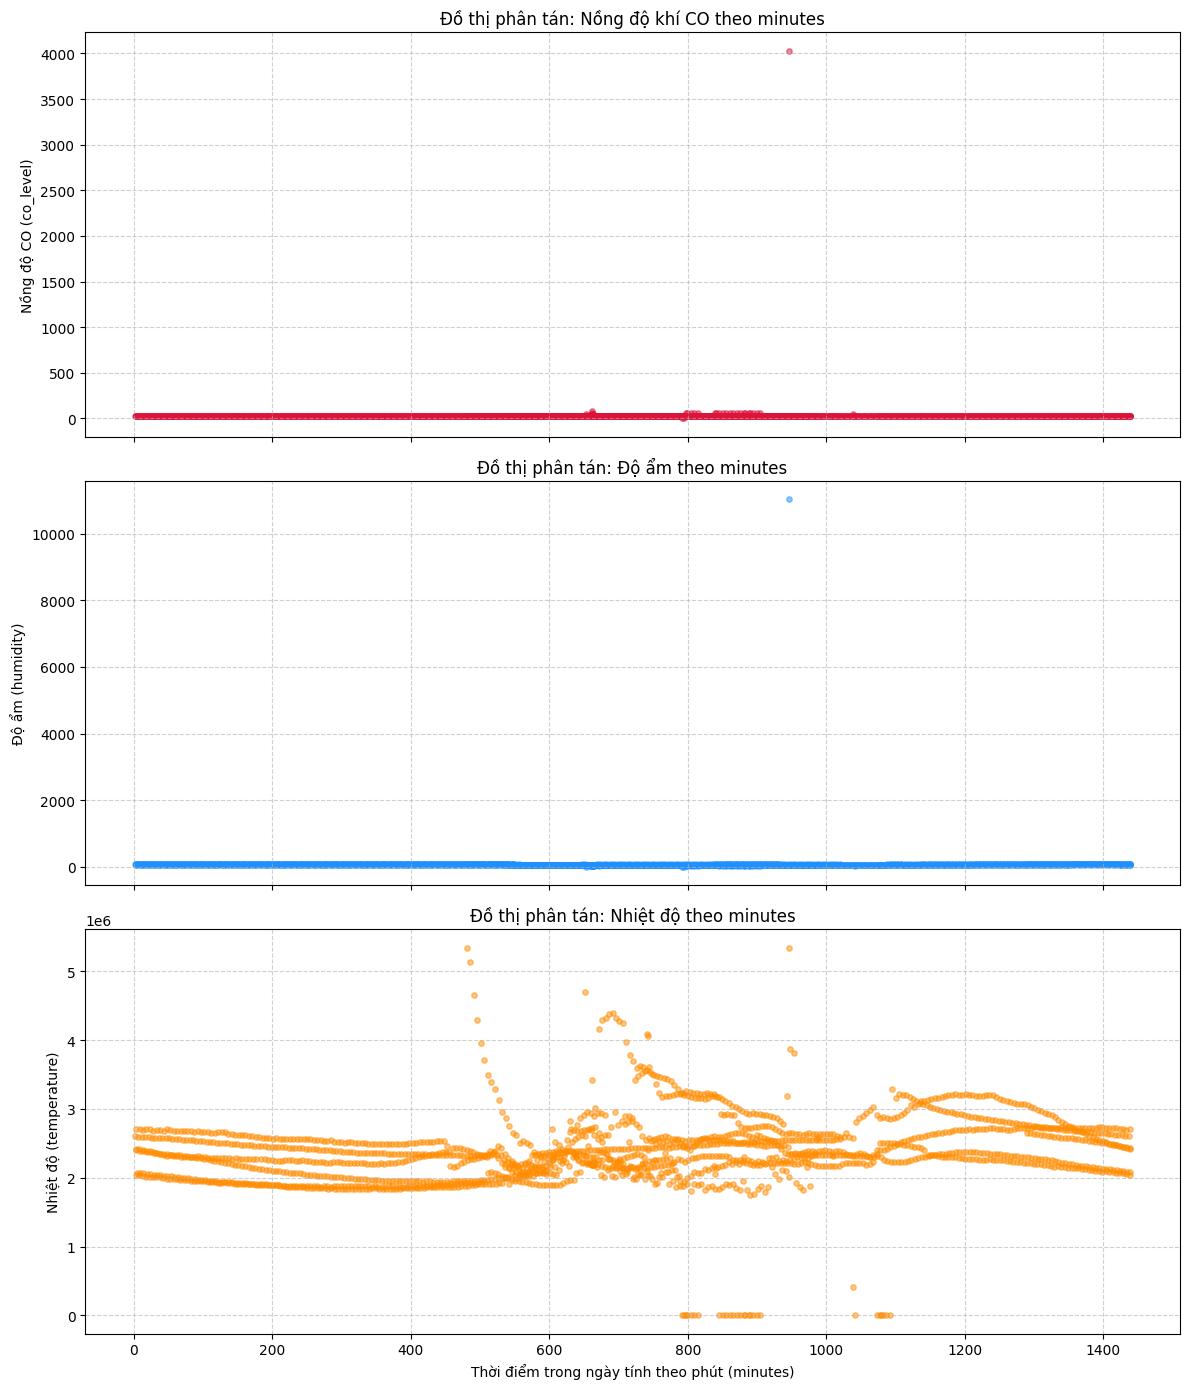

In [4]:
# In thông tin sinh viên theo yêu cầu
print("Họ và tên: Vũ Trương Phi")
print("MSSV: 6451071059")
print("-" * 40)

import matplotlib.pyplot as plt

# Thiết lập hiển thị 3 đồ thị phân tán
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(12, 14), sharex=True)

# 1. Đồ thị phân tán biểu diễn co_level theo minutes
axes[0].scatter(df['minutes'], df['co_level'], color='crimson', alpha=0.5, s=15)
axes[0].set_title('Đồ thị phân tán: Nồng độ khí CO theo minutes')
axes[0].set_ylabel('Nồng độ CO (co_level)')
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Đồ thị phân tán biểu diễn humidity theo minutes
axes[1].scatter(df['minutes'], df['humidity'], color='dodgerblue', alpha=0.5, s=15)
axes[1].set_title('Đồ thị phân tán: Độ ẩm theo minutes')
axes[1].set_ylabel('Độ ẩm (humidity)')
axes[1].grid(True, linestyle='--', alpha=0.6)

# 3. Đồ thị phân tán biểu diễn temperature theo minutes
axes[2].scatter(df['minutes'], df['temperature'], color='darkorange', alpha=0.5, s=15)
axes[2].set_title('Đồ thị phân tán: Nhiệt độ theo minutes')
axes[2].set_xlabel('Thời điểm trong ngày tính theo phút (minutes)')
axes[2].set_ylabel('Nhiệt độ (temperature)')
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()